# Step 1 - Understanding the problem
**Goal:** detect abnormal power behaviour of household appliances (sudden spike/drop, unusual power level).
**Why unsupervised:** UK-DALE has no fault labels, so we learn what *normal* looks like and flag deviations.
**Pipeline:** data -> cleaning -> features -> model (IF / LOF / OCSVM) -> evaluation + statistics -> Flask dashboard.
# Step 2 - Understanding the data (UK-DALE)
5 UK houses, appliance-level active power (W) sampled about every 6 s. File format: `timestamp power`.

In [1]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
SEED = 42; np.random.seed(SEED)                       # reproducibility
UKDALE_DIR = os.environ.get("UKDALE_DIR", "../ukdale")
HOUSE = "house_1"
APPS = {"washing_machine": 5, "kettle": 10, "fridge": 12, "microwave": 13}   # house_1 channels
THRESH = {"washing_machine": 30, "kettle": 50, "fridge": 20, "microwave": 20}  # ON/OFF threshold (W)
WINDOW_DAYS = 90                                       # sampling window (see sampling note below)
os.makedirs("../data", exist_ok=True); sns.set_theme()

## 2.1 What is in the download?

In [2]:
print(sorted(os.listdir(UKDALE_DIR)))
for h in sorted(os.listdir(UKDALE_DIR)):
    p = os.path.join(UKDALE_DIR, h)
    if h.startswith("house"):
        print(h, "->", len([f for f in os.listdir(p) if f.endswith(".dat")]), ".dat files")

['house_1', 'house_2', 'house_3', 'house_4', 'house_5', 'metadata']
house_1 -> 103 .dat files
house_2 -> 32 .dat files
house_3 -> 6 .dat files
house_4 -> 7 .dat files
house_5 -> 39 .dat files


In [3]:
labels = pd.read_csv(os.path.join(UKDALE_DIR, HOUSE, "labels.dat"), sep=" ", names=["channel", "name"])
labels

,channel,name
0,1,aggregate
1,2,boiler
2,3,solar_thermal_pump
3,4,laptop
4,5,washing_machine
5,6,dishwasher
6,7,tv
7,8,kitchen_lights
8,9,htpc
9,10,kettle


## 2.2 Load a sample window
**Sampling note:** the full files hold millions of rows (years of data). We use house_1, 4 appliances and the first
90 days of each file (fixed window -> reproducible, memory-friendly). Files are read in chunks and loading stops early.

In [4]:
def load_window(app, days=WINDOW_DAYS):
    f = f"{UKDALE_DIR}/{HOUSE}/channel_{APPS[app]}.dat"
    parts, start = [], None
    for ch in pd.read_csv(f, sep=" ", names=["ts", "power"], chunksize=1_000_000):
        if start is None: start = ch.ts.iloc[0]
        end = start + days * 86400
        parts.append(ch[ch.ts < end])
        if ch.ts.iloc[-1] >= end: break
    df = pd.concat(parts)
    df.index = pd.to_datetime(df.pop("ts"), unit="s")
    return df

raw = {a: load_window(a) for a in APPS}
{a: len(d) for a, d in raw.items()}

{'washing_machine': 784321,
 'kettle': 577822,
 'fridge': 924599,
 'microwave': 925857}

## 2.3 Data quality summary (what preprocessing must fix)

In [5]:
rows = []
for a, d in raw.items():
    dt = d.index.to_series().diff().dt.total_seconds().dropna()
    rows.append(dict(appliance=a, rows=len(d), start=d.index[0], end=d.index[-1], median_dt_s=dt.median(),
                     gaps_over_60s=int((dt > 60).sum()), duplicate_ts=int(d.index.duplicated().sum()),
                     negatives=int((d.power < 0).sum()), missing=int(d.power.isna().sum()),
                     max_W=d.power.max(), mean_W=round(float(d.power.mean()), 1)))
summary = pd.DataFrame(rows).set_index("appliance"); summary

,rows,start,end,median_dt_s,gaps_over_60s,duplicate_ts,negatives,missing,max_W,mean_W
appliance,,,,,,,,,,
washing_machine,784321,2012-11-09 22:28:18,2013-02-07 04:00:04,6.0,73,0,0,0,3900,24.3
kettle,577822,2012-11-09 22:28:18,2013-02-07 04:00:03,6.0,97,0,0,0,2676,16.2
fridge,924599,2012-12-14 22:21:32,2013-03-14 22:21:25,6.0,75,0,0,0,2984,35.6
microwave,925857,2012-12-14 22:21:33,2013-03-14 22:21:29,6.0,76,0,0,0,2898,6.6


## 2.4 First graphs

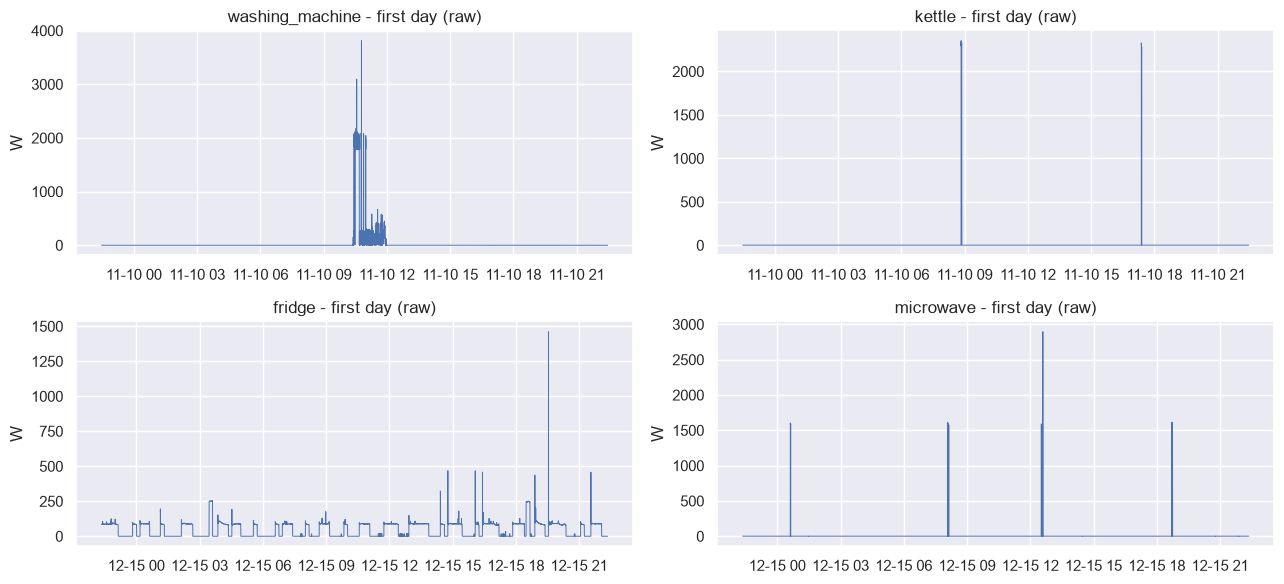

In [6]:
fig, ax = plt.subplots(2, 2, figsize=(13, 6))
for a_, (a, d) in zip(ax.ravel(), raw.items()):
    day = d.loc[d.index[0]: d.index[0] + pd.Timedelta(days=1)]
    a_.plot(day.index, day.power, lw=.7); a_.set_title(f"{a} - first day (raw)"); a_.set_ylabel("W")
plt.tight_layout(); plt.savefig("../data/fig_raw_first_day.png", dpi=120); plt.show()

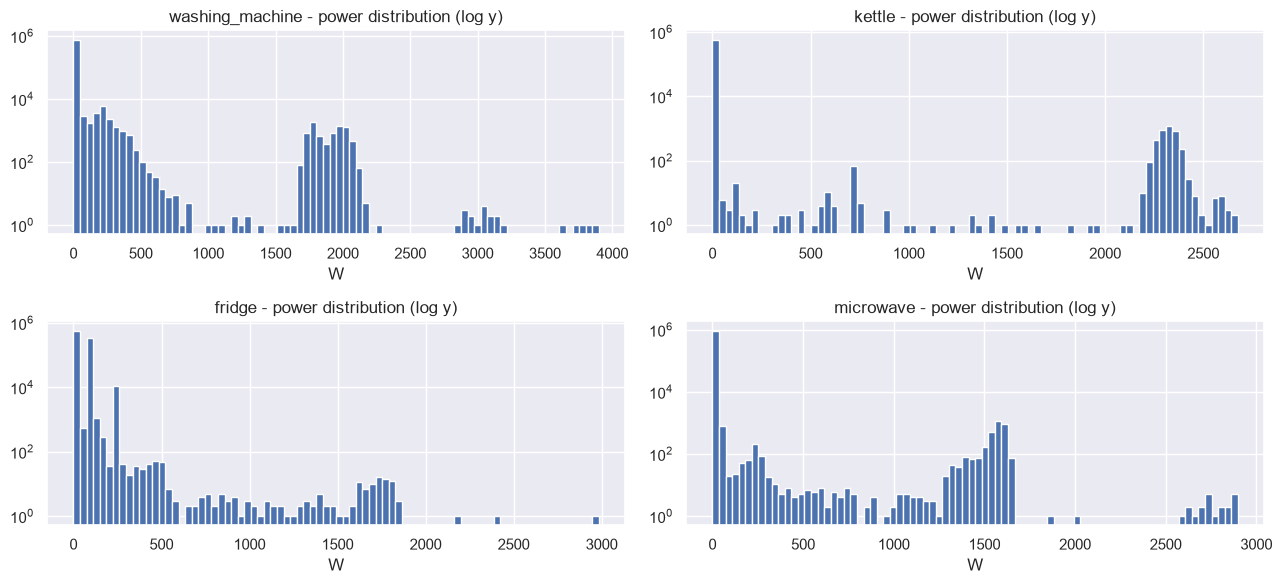

In [7]:
fig, ax = plt.subplots(2, 2, figsize=(13, 6))
for a_, (a, d) in zip(ax.ravel(), raw.items()):
    a_.hist(d.power, bins=80); a_.set_yscale("log"); a_.set_title(f"{a} - power distribution (log y)"); a_.set_xlabel("W")
plt.tight_layout(); plt.savefig("../data/fig_distribution.png", dpi=120); plt.show()

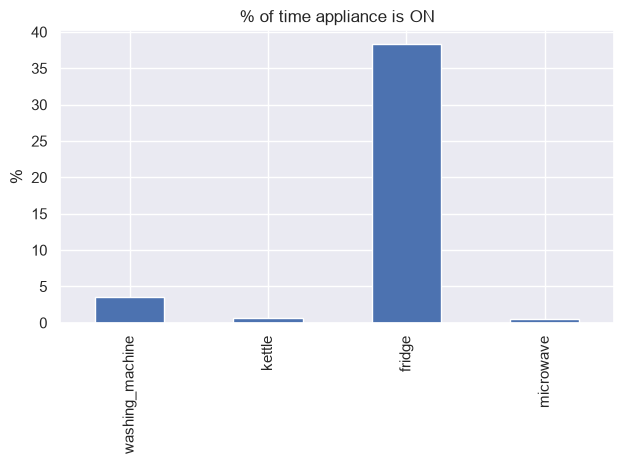

washing_machine     3.60
kettle              0.68
fridge             38.29
microwave           0.49
dtype: float64

In [8]:
on_share = pd.Series({a: (d.power > THRESH[a]).mean() * 100 for a, d in raw.items()})
on_share.plot.bar(title="% of time appliance is ON", ylabel="%"); plt.tight_layout(); plt.show()
on_share.round(2)